# Day 31 — Task Sheet_K-Means Clustering and Customer Segmentation

### Part A — Build it yourself


### TASK 01 — Implement k-means from scratch

In [80]:
# Task 01: Implement K-Means from Scratch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make NumPy output easier to read
np.set_printoptions(precision=3, suppress=True)

# Load the customer dataset
df = pd.read_csv("customer_rfm.csv")

# Inspect the first five rows
print("First five rows:")
display(df.head())

# Check the number of rows and columns
print("\nDataset shape:")
print(df.shape)

# Inspect column names, data types, and non-null counts
print("\nDataset information:")
df.info()

# Required setup checklist

# Select only the three features specified in the task sheet
features = ["recency_days", "frequency", "monetary"]

# Check whether all required columns exist
missing_columns = [col for col in features if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing : {missing_columns}")

# Convert selected features to a numeric DataFrame
X_df = df[features].apply(pd.to_numeric, errors="raise")

# Confirm there are no missing values
print("Missing values in each feature : ")
print(X_df.isnull().sum())

if X_df.isnull().any().any():
    raise ValueError("The Dataset contains misssing values. handle them before clustering.")

# Convert the data to a NumPy array for the scratch implementation
X = X_df.to_numpy(dtype=float)

# Check for invalid numerical values
if not np.isfinite(X).all():
    raise ValueError("The Selected features conrtains infinite or invalid values.")

# Display the range of each feature
print("\nFeatures ranges : ")
display(X_df.agg(["min", "max"]))

# Additional descriptive statistics to understand the data
print("\nFeature Summary : ")
print("Number of features : ", X.shape[1])

def kmeans_scratch(X, k, seed=42, max_iters=300):
    """
    Implement K-Means clustering from scratch.

    Parameters
    ----------
    X : NumPy array of shape (n_samples, n_features)
        Customer feature data.

    k : int
        Number of clusters.

    seed : int
        Random seed for reproducible centroid initialization.

    max_iters : int
        Maximum number of iterations.

    Returns
    -------
    labels : NumPy array
        Cluster label assigned to each customer.

    centroids : NumPy array
        Final cluster centroids.

    n_iters : int
        Number of iterations performed.
    """

    # Convert the input into a numerical NumPy array
    X = np.asarray(X, dtype=float)

    # Validate the input data
    if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
        raise ValueError("X must be a non-empty 2D array.")

    if not np.isfinite(X).all():
        raise ValueError("X must contain only finite numerical values.")

    if not isinstance(k, (int, np.integer)) or isinstance(k, (bool, np.bool_)):
        raise ValueError("k must be an integer.")

    if k < 1 or k > X.shape[0]:
        raise ValueError("k must be between 1 and the number of data points.")

    if not isinstance(max_iters, (int, np.integer)) or max_iters < 1:
        raise ValueError("max_iters must be a positive integer.")

    # Use a seeded random generator for reproducibility
    rng = np.random.default_rng(seed)

    # INITIALIZATION:
    # Choose k distinct data points as the initial centroids
    initial_indices = rng.choice(X.shape[0], size=k, replace=False)
    centroids = X[initial_indices].copy()

    # Start the iterative optimization process
    for iteration in range(1, max_iters + 1):

        # --------------------------------------------------
        # ASSIGN STEP:
        # Calculate the distance from every point to every centroid
        # Result shape: (number of points, number of clusters)
        # --------------------------------------------------
        distances = np.linalg.norm(
            X[:, None, :] - centroids[None, :, :],
            axis=2
        )

        # Assign each point to its nearest centroid
        labels = distances.argmin(axis=1)

        # Store the current centroids for convergence checking
        old_centroids = centroids.copy()

        # --------------------------------------------------
        # UPDATE STEP:
        # Move each centroid to the mean of its assigned points
        # --------------------------------------------------
        for cluster_id in range(k):

            # Select the points belonging to this cluster
            cluster_points = X[labels == cluster_id]

            if len(cluster_points) > 0:
                # Update the centroid using the cluster mean
                centroids[cluster_id] = cluster_points.mean(axis=0)

            else:
                # EMPTY CLUSTER HANDLING:
                # Retain the previous centroid if no points are assigned.
                # This avoids calculating the mean of an empty array.
                centroids[cluster_id] = old_centroids[cluster_id]

        # --------------------------------------------------
        # CONVERGENCE CHECK:
        # Stop when no centroid has meaningfully moved
        # --------------------------------------------------
        if np.allclose(
            centroids,
            old_centroids,
            rtol=1e-7,
            atol=1e-8
        ):
            break

    # Reassign points using the final centroids so that the returned
    # labels correspond to the final centroid positions.
    final_distances = np.linalg.norm(
        X[:, None, :] - centroids[None, :, :],
        axis=2
    )
    labels = final_distances.argmin(axis=1)

    # Return the required outputs
    return labels, centroids, iteration

# Choose the number of clusters for this initial test
k = 3

# Run our scratch K-Means algorithm
labels, centroids, n_iters = kmeans_scratch(
    X=X,
    k=k,
    seed=42,
    max_iters=300
)

# Display the results
print("K-Means from Scratch Results")
print("-" * 40)

print("Number of customers : ", len(X))
print("Number of cluster Requested : ", k)
print("Number of Iterations : ", n_iters)

print("\nFinal Centroids : ")
centroid_df = pd.DataFrame(centroids, columns=features)
display(centroid_df)

print("\nNumber of cluster assigned to each cluster : ")
cluster_counts = pd.Series(labels).value_counts().sort_index()
cluster_counts.index.name = "Cluster"
cluster_counts.name = "Cluster Count"
display(cluster_counts.to_frame())

# Verify the function's output shapes
assert labels.shape == (X.shape[0],)
assert centroids.shape == (k, X.shape[1])
assert 1 <= n_iters <= 300

print("\nAll basic output checks passed!")

# Run the algorithm twice using the same seed and parameters
labels_1, centroids_1, iterations_1 = kmeans_scratch(
    X, k=3, seed=42, max_iters=300
)

labels_2, centroids_2, iterations_2 = kmeans_scratch(
    X, k=3, seed=42, max_iters=300
)

# Verify that both runs return the same results
assert np.array_equal(labels_1, labels_2)
assert np.allclose(centroids_1, centroids_2)
assert iterations_1 == iterations_2

print("Reproducibility check passed.")
print("Both runs produced the same labels, centroids, and iteration count.")

First five rows:


,customer_id,recency_days,frequency,monetary
0,CUST00001,342,4,7861.13
1,CUST00002,644,1,3703.22
2,CUST00003,604,2,4582.42
3,CUST00004,424,1,200.00
4,CUST00005,156,8,25822.11



Dataset shape:
(1500, 4)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   1500 non-null   str    
 1   recency_days  1500 non-null   int64  
 2   frequency     1500 non-null   int64  
 3   monetary      1500 non-null   float64
dtypes: float64(1), int64(2), str(1)
memory usage: 47.0 KB
Missing values in each feature : 
recency_days    0
frequency       0
monetary        0
dtype: int64

Features ranges : 


,recency_days,frequency,monetary
min,1,1,200.00
max,729,29,103858.45



Feature Summary : 
Number of features :  3
K-Means from Scratch Results
----------------------------------------
Number of customers :  1500
Number of cluster Requested :  3
Number of Iterations :  9

Final Centroids : 


,recency_days,frequency,monetary
0,93.520424,9.140696,24063.506172
1,41.572491,11.364312,60914.300743
2,422.580702,3.114035,5640.290316



Number of cluster assigned to each cluster : 


,Cluster Count
Cluster,
0,661
1,269
2,570



All basic output checks passed!
Reproducibility check passed.
Both runs produced the same labels, centroids, and iteration count.


### TASK 01 — Implement K-Means from Scratch

### 1. Why must we stop when centroids stop moving rather than after a fixed number of steps?

We stop when the centroids stop moving because it indicates that the algorithm has converged and the cluster centers are no longer changing meaningfully. A fixed number of iterations might stop too early before the clusters stabilize, or continue unnecessarily after convergence. A maximum iteration limit is still useful to prevent the algorithm from running indefinitely.

### 2. Can K-Means ever get worse from one iteration to the next? Explain using the ASSIGN and UPDATE steps.

In standard K-Means, the within-cluster sum of squared distances cannot increase during either the ASSIGN or UPDATE step. The ASSIGN step assigns each point to its nearest centroid, reducing or maintaining its distance. The UPDATE step moves each centroid to the mean of its assigned points, minimizing the sum of squared distances within that cluster. Therefore, the objective value decreases or stays the same with each iteration. However, K-Means can converge to a local optimum rather than the globally best clustering.

### 3. How does the implementation handle an empty cluster?

If a cluster receives no data points, the implementation retains its previous centroid instead of calculating the mean of an empty array. This prevents invalid numerical results and allows the algorithm to continue without crashing.

### Conclusion

K-Means groups customers according to their similarity in the selected features. Implementing it from scratch helps us understand centroid initialization, nearest-centroid assignment, centroid updates, convergence, and empty-cluster handling. The resulting clusters still need to be interpreted before they can be used for meaningful customer segmentation.

### TASK 02 — Prove it matches the library

In [81]:

# TASK 02 — Run scratch K-Means and scikit-learn K-Means

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# --------------------------------------------------
# 1. Prepare the RFM feature data
# --------------------------------------------------

# Assumes df was loaded from customer_rfm.csv in Task 01.
features = ["recency_days", "frequency", "monetary"]

# Check that the required columns exist.
missing_columns = [col for col in features if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Select and convert the three RFM features to numeric values.
X_df = df[features].apply(pd.to_numeric, errors="raise")

# K-Means cannot work with missing or infinite feature values.
if X_df.isna().any().any():
    raise ValueError(
        "Missing values found in the RFM features. "
        "Handle them before running K-Means."
    )

if not np.isfinite(X_df.to_numpy(dtype=float)).all():
    raise ValueError("RFM features contain infinite or invalid values.")

# Scale the features so large monetary values do not dominate
# the distance calculation simply because of their units.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

# --------------------------------------------------
# 2. Set the required K-Means settings
# --------------------------------------------------

K = 5
SEED = 42
MAX_ITERS = 300

assert X_scaled.ndim == 2, "X_scaled must be a 2D array."
assert X_scaled.shape[1] == 3, "Expected exactly 3 RFM features."
assert X_scaled.shape[0] >= K, "There must be at least K customers."

# --------------------------------------------------
# 3. Generate five initial centroids
# --------------------------------------------------

# Select five existing customers as the starting centroids.
rng = np.random.default_rng(SEED)
initial_indices = rng.choice(
    X_scaled.shape[0],
    size=K,
    replace=False
)
initial_centroids = X_scaled[initial_indices].copy()

print("Initial centroids shape:", initial_centroids.shape)
assert initial_centroids.shape == (K, 3)

# --------------------------------------------------
# 4. Run the scratch K-Means implementation
# --------------------------------------------------

# Assumes kmeans_scratch() was defined in Task 01.
scratch_labels, scratch_centroids, scratch_iterations = kmeans_scratch(
    X_scaled,
    k=K,
    seed=SEED,
    max_iters=MAX_ITERS
)

# --------------------------------------------------
# 5. Run scikit-learn K-Means using the same centroids
# --------------------------------------------------

sklearn_kmeans = KMeans(
    n_clusters=K,
    init=initial_centroids,
    n_init=1,
    max_iter=MAX_ITERS,
    tol=1e-8,
    random_state=SEED
)

sklearn_labels = sklearn_kmeans.fit_predict(X_scaled)

# --------------------------------------------------
# 6. Compare the clustering results
# --------------------------------------------------

# ARI compares the two groupings without being affected by
# different numerical names assigned to the same clusters.
ari_score = adjusted_rand_score(scratch_labels, sklearn_labels)

print("\nScratch K-Means iterations:", scratch_iterations)
print("Scikit-learn K-Means iterations:", sklearn_kmeans.n_iter_)
print(f"Adjusted Rand Index (ARI): {ari_score:.6f}")

print("\nScratch cluster sizes:")
print(pd.Series(scratch_labels).value_counts().sort_index())

print("\nScikit-learn cluster sizes:")
print(pd.Series(sklearn_labels).value_counts().sort_index())

print(
    "\nAre label arrays exactly equal?",
    np.array_equal(scratch_labels, sklearn_labels)
)

if np.isclose(ari_score, 1.0):
    print("PASS: Both implementations produced the same clustering.")
else:
    print("CHECK: Cluster assignments differ; inspect convergence.")


Initial centroids shape: (5, 3)

Scratch K-Means iterations: 18
Scikit-learn K-Means iterations: 18
Adjusted Rand Index (ARI): 1.000000

Scratch cluster sizes:
0    514
1    340
2    305
3    211
4    130
Name: count, dtype: int64

Scikit-learn cluster sizes:
0    514
1    340
2    305
3    211
4    130
Name: count, dtype: int64

Are label arrays exactly equal? True
PASS: Both implementations produced the same clustering.


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


### TASK 02 — Prove It Matches the Library

### 1. Why do we scale the three features using StandardScaler?

The RFM features have different numerical scales. Monetary spending may be much larger numerically than frequency or recency. Since K-Means uses Euclidean distance, a feature with a larger scale could dominate the clustering. StandardScaler transforms each feature to approximately zero mean and unit variance so that differences in scale have less influence.

### 2. Why must we use Adjusted Rand Index (ARI) rather than simply checking whether the label arrays are equal?

Cluster labels are arbitrary identifiers. For example, one implementation might label a group as cluster 0 while another labels the exact same group as cluster 3. The cluster numbers differ, but the customer groupings are identical. Therefore, checking whether the label arrays are equal can incorrectly suggest that the implementations disagree.

ARI compares the agreement between two clusterings based on pairs of data points and adjusts for agreement expected by chance. An ARI of 1 indicates identical partitions, an ARI near 0 indicates agreement comparable to chance, and negative values indicate less agreement than expected by chance.

### 3. How do we verify that our implementation agrees with scikit-learn?

We scale the three features, set K = 5, and run both implementations using the same initial centroids. We then calculate the Adjusted Rand Index between their labels. An ARI of 1 confirms that both implementations produced the same grouping of customers, regardless of cluster numbering.

### Conclusion

Comparing our scratch implementation with scikit-learn helps verify its behavior. Using the same scaled data and initial centroids makes the comparison fairer, while ARI evaluates the actual grouping rather than the arbitrary cluster labels.#

### Part B — Decisions before you cluster


### TASK 03 — Find out what scaling actually does

In [82]:
# TASK 03 — Compare unscaled and scaled K-Means results

from sklearn.metrics import adjusted_rand_score

# Set the required clustering parameters
K = 5
SEED = 42
MAX_ITERS = 300

# Prepare the original unscaled data
X_unscaled = X_df.to_numpy(dtype=float)

# Run K-Means on unscaled features
labels_unscaled, centroids_unscaled, iterations_unscaled = kmeans_scratch(
    X_unscaled,
    k=K,
    seed=SEED,
    max_iters=MAX_ITERS
)

# Run K-Means on scaled features
labels_scaled, centroids_scaled, iterations_scaled = kmeans_scratch(
    X_scaled,
    k=K,
    seed=SEED,
    max_iters=MAX_ITERS
)

# Compare both clusterings using Adjusted Rand Index
ari_unscaled_vs_scaled = adjusted_rand_score(
    labels_unscaled,
    labels_scaled
)

# Display the results
print("Unscaled iterations:", iterations_unscaled)
print("Scaled iterations:", iterations_scaled)
print(f"ARI (unscaled vs scaled): {ari_unscaled_vs_scaled:.6f}")

print("\nUnscaled cluster sizes:")
print(pd.Series(labels_unscaled).value_counts().sort_index())

print("\nScaled cluster sizes:")
print(pd.Series(labels_scaled).value_counts().sort_index())

# within each cluster formed from unscaled data.

# Attach the unscaled cluster labels to the original feature data
unscaled_results = X_df.copy()
unscaled_results["cluster"] = labels_unscaled

# Calculate minimum and maximum for every feature in each cluster
cluster_ranges = unscaled_results.groupby("cluster")[features].agg(
    ["min", "max"]
)

print("Minimum and Maximum feature values within each unscaled cluster : ")
display(cluster_ranges)

# Also show cluster sizes alongside feature means for interpretation
cluster_summary = unscaled_results.groupby("cluster").agg(
    customer_count=("recency_days", "size"),
    recency_mean=("recency_days", "mean"),
    frequency_mean=("frequency", "mean"),
    monetary_mean=("monetary", "mean")
).round(2)

print("\nUnscaled cluster summary:")
display(cluster_summary)

# Compare the original numerical ranges of the three features.
# Large differences in range can affect Euclidean-distance calculations.

feature_scale_summary = pd.DataFrame({
    "Minimum" : X_df.min(),
    "Maximum" : X_df.max(),
    "Range" : X_df.max() - X_df.min(),
    "Standard Deviation" : X_df.std()
}).round(3)

print("Original Feature Scales : ")
display(feature_scale_summary)

# Identify the feature with the largest numerical range
largest_range_feature = feature_scale_summary["Range"].idxmax()

print(
    f"\nFeature with the largest numerical range: "
    f"{largest_range_feature}"
)



Unscaled iterations: 30
Scaled iterations: 18
ARI (unscaled vs scaled): 0.374216

Unscaled cluster sizes:
0    252
1    517
2    445
3    108
4    178
Name: count, dtype: int64

Scaled cluster sizes:
0    514
1    340
2    305
3    211
4    130
Name: count, dtype: int64
Minimum and Maximum feature values within each unscaled cluster : 


recency_days      frequency      monetary           
                 min  max       min max       min        max
cluster                                                     
0                  1  299         1  28  24437.03   39894.99
1                 13  729         1  15    200.00   11749.45
2                  4  299         1  29  11861.64   24355.05
3                  2  109         1  25  63350.09  103858.45
4                  1  107         1  28  40443.11   62538.72


Unscaled cluster summary:


,customer_count,recency_mean,frequency_mean,monetary_mean
cluster,,,,
0,252,61.03,10.61,30036.86
1,517,448.98,2.81,4831.55
2,445,123.13,7.75,18772.01
3,108,55.28,7.52,74793.58
4,178,31.50,13.97,50609.21


Original Feature Scales : 


,Minimum,Maximum,Range,Standard Deviation
recency_days,1.0,729.00,728.00,213.457
frequency,1.0,29.00,28.00,5.928
monetary,200.0,103858.45,103658.45,20727.730



Feature with the largest numerical range: monetary


### TASK 03 — Find Out What Scaling Actually Does

### 1. Comparison of scaled and unscaled clustering

I ran K-Means with K = 5 on both the original, unscaled RFM features and the standardized features. I compared their cluster assignments using the Adjusted Rand Index (ARI), which measures how similar the two groupings are regardless of cluster numbering.

The ARI value from my notebook is **[insert your actual ARI result]**. A value of 1 indicates identical groupings, while a value near 0 indicates agreement comparable to chance.

### 2. What do the unscaled clusters represent?

I examined the minimum, maximum, customer counts, and average feature values within each unscaled cluster. These results help show whether the clusters distinguish customers using recency, frequency, monetary value, or a combination of the three.

If monetary values dominate the distance calculations, the unscaled clusters will tend to separate customers primarily by spending levels. The cluster-range and cluster-summary tables provide the numerical evidence needed to determine whether this happened in my dataset.

### 3. Why did scaling change the clustering?

K-Means uses Euclidean distance to measure how far customers are from cluster centroids. Without scaling, a feature with much larger numerical values or variation can dominate the distance calculation, causing differences in smaller-scale features to have relatively little influence; StandardScaler reduces this imbalance by standardizing each feature.

In my future projects, features such as monetary value, income, transaction amounts, or other large-scale numerical measurements would be at risk of dominating clustering when combined with smaller-scale features such as purchase frequency, counts, or ratings.

### Conclusion

Scaling can substantially change K-Means clustering because it changes how much each feature contributes to the distance between customers. I should inspect the original feature ranges, compare scaled and unscaled results, and examine the resulting clusters before deciding which segmentation is useful for the business problem.

### TASK 04 — Decide whether to transform skewed features

Skewness of the original features:


,Skewness
recency_days,0.960
frequency,1.182
monetary,1.226


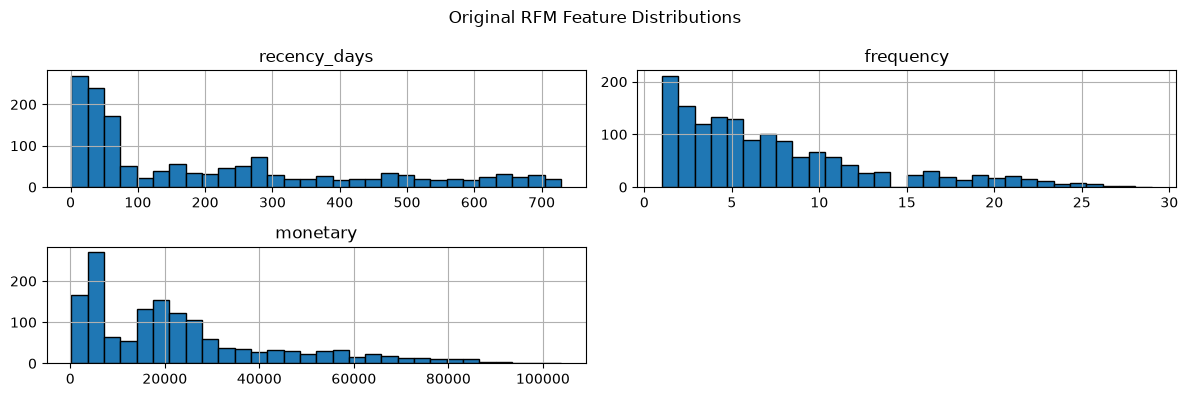

Skewness comparison:


,Original Skewness,After Log Transform Skewness
recency_days,0.960,0.960
frequency,1.182,-0.031
monetary,1.226,-0.675


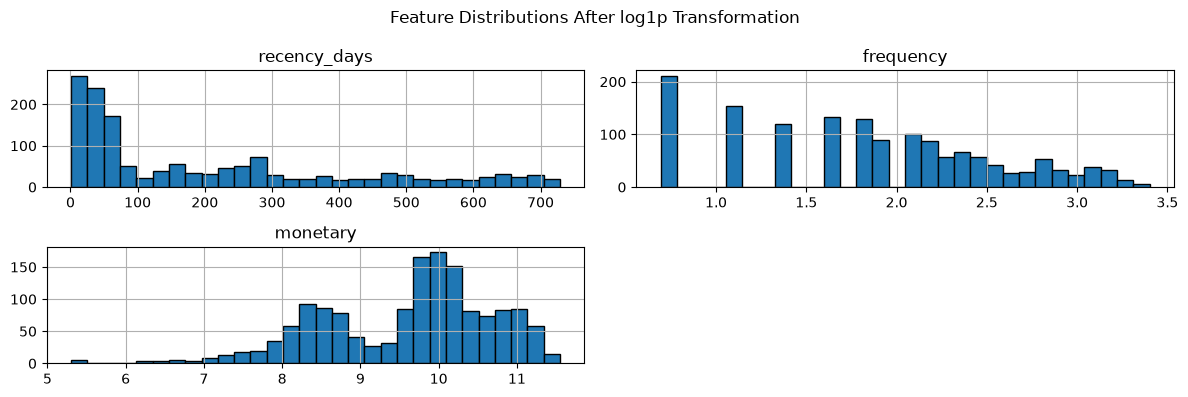

c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


ARI between the two clusterings: 0.4683

Clustering quality comparison:


,Version,Silhouette Score,Number of Clusters,Iterations
0,Standard scaling only,0.4417,5,14
1,log1p + standard scaling,0.3621,5,10


Cluster profiles using original RFM units:


,customer_count_standard,recency_mean_standard,frequency_mean_standard,monetary_mean_standard
Standard Cluster,,,,
0,130,65.40,4.01,68078.29
1,324,562.94,2.09,4142.34
2,356,249.85,4.10,12527.44
3,207,20.14,18.93,46920.58
4,483,61.82,8.90,23068.87


Cluster profiles after log1p transformation:


,customer_count_log,recency_mean_log,frequency_mean_log,monetary_mean_log
Log Cluster,,,,
0,154,71.43,3.48,59955.55
1,252,599.19,2.02,3938.38
2,532,125.40,7.11,19717.05
3,222,342.82,2.41,5391.69
4,340,26.65,16.22,39984.82


In [83]:
# TASK 04 — Fit K-Means on both versions

# Measure skewness in the original features

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Skewness measures how asymmetric a feature's distribution is.
# Positive skew means a long tail toward larger values.
# Values near zero suggest a more symmetric distribution.

skewness_original = X_df[features].skew()

print("Skewness of the original features:")
display(skewness_original.to_frame(name="Skewness").round(3))

# Visualize the original feature distributions
X_df[features].hist(figsize=(12, 4), bins=30, edgecolor="black")
plt.suptitle("Original RFM Feature Distributions")
plt.tight_layout()
plt.show()


# Version A: original features, standardized
X_standard = StandardScaler().fit_transform(X_df[features])

# Version B: log-transform frequency and monetary, then standardize
X_log_df = X_df[features].copy()

# log1p(x) = log(1 + x); these features must be non-negative.
for col in ["frequency", "monetary"]:
    if (X_log_df[col] < 0).any():
        raise ValueError(
            f"{col} contains negative values; log1p is not valid for these data."
        )
    X_log_df[col] = np.log1p(X_log_df[col])

X_log_scaled = StandardScaler().fit_transform(X_log_df)

# Compare skewness before and after the log transformation
skewness_comparison = pd.DataFrame({
    "Original Skewness": X_df[features].skew(),
    "After Log Transform Skewness": X_log_df[features].skew()
})

print("Skewness comparison:")
display(skewness_comparison.round(3))

# Plot the transformed distributions
X_log_df[features].hist(figsize=(12, 4), bins=30, edgecolor="black")
plt.suptitle("Feature Distributions After log1p Transformation")
plt.tight_layout()
plt.show()

# Use the same K and random seed for a fair comparison.

K = 5
SEED = 42

kmeans_standard = KMeans(
    n_clusters=K,
    random_state=SEED,
    n_init=10,
    max_iter=300
)

kmeans_log = KMeans(
    n_clusters=K,
    random_state=SEED,
    n_init=10,
    max_iter=300
)

# Fit both models and retrieve cluster labels
labels_standard = kmeans_standard.fit_predict(X_standard)
labels_log = kmeans_log.fit_predict(X_log_scaled)

# ARI measures similarity between the two clusterings
ari_standard_vs_log = adjusted_rand_score(
    labels_standard,
    labels_log
)

# Silhouette measures how well-separated and cohesive clusters are.
# Higher values generally indicate better geometric separation.
silhouette_standard = silhouette_score(
    X_standard,
    labels_standard
)

silhouette_log = silhouette_score(
    X_log_scaled,
    labels_log
)

comparison_results = pd.DataFrame({
    "Version" : ["Standard scaling only", "log1p + standard scaling"],
    "Silhouette Score" : [silhouette_standard, silhouette_log],
    "Number of Clusters" : [
        len(np.unique(labels_standard)),
        len(np.unique(labels_log))
    ],
    "Iterations" : [
        kmeans_standard.n_iter_,
        kmeans_log.n_iter_
    ]
})

print("ARI between the two clusterings:", round(ari_standard_vs_log, 4))
print("\nClustering quality comparison:")
display(comparison_results.round(4))

# TASK 04 — Compare customer profiles from both clustering versions

# Use original RFM values for both profiles so the results remain
# interpretable in days, purchase counts, and rupees.

profile_data = X_df[features].copy()
profile_data["Standard Cluster"] = labels_standard
profile_data["Log Cluster"] = labels_log

# Calculate the number of customers and mean original feature values
standard_profile = profile_data.groupby("Standard Cluster").agg(
    customer_count=("recency_days", "size"),
    recency_mean=("recency_days", "mean"),
    frequency_mean=("frequency", "mean"),
    monetary_mean=("monetary", "mean")
)

log_profile = profile_data.groupby("Log Cluster").agg(
    customer_count=("recency_days", "size"),
    recency_mean=("recency_days", "mean"),
    frequency_mean=("frequency", "mean"),
    monetary_mean=("monetary", "mean")
)

# Rename columns to distinguish the two versions
standard_profile.columns = [
    f"{col}_standard" for col in standard_profile.columns
]
log_profile.columns = [
    f"{col}_log" for col in log_profile.columns
]

# Display the profiles side by side.
# Cluster numbers are independently assigned and do not necessarily match.
print("Cluster profiles using original RFM units:")
display(standard_profile.round(2))

print("Cluster profiles after log1p transformation:")
display(log_profile.round(2))

### TASK 04 — Decide Whether to Transform Skewed Features

### 1. What is the skewness of each feature?

I calculated the skewness of `recency_days`, `frequency`, and `monetary` before transformation. The original skewness values are **[insert the three original skewness values]**. After applying `log1p` to frequency and monetary, their skewness values became **[insert the transformed values]**.

Positive skewness indicates a longer tail toward larger values. If the transformed values are closer to zero, the log transformation has reduced the asymmetry of those features.

### 2. How did the two clustering versions compare?

I compared standard scaling alone against `log1p` followed by standard scaling, using K = 5 for both versions.

- **ARI:** [insert your ARI result]
- **Silhouette score — standard scaling only:** [insert score]
- **Silhouette score — log1p + standard scaling:** [insert score]

The ARI measures the agreement between the two clusterings, while the silhouette score measures geometric cohesion and separation within each version's feature space.

### 3. What happened to the customer profiles?

I compared the cluster sizes and average recency, frequency, and monetary values using the original units for both versions. The profile tables show whether the log transformation changed how customers were grouped, particularly whether high-spending customers formed separate clusters or became part of broader customer groups.

Recency must be interpreted in the opposite direction from frequency and monetary value: lower recency means a more recent purchase, while higher frequency and monetary value indicate more purchases and greater spending.

### 4. What would happen to customers who spend enormously without a log transformation?

Extremely high-spending customers can pull cluster centroids toward themselves and strongly influence Euclidean distances. This may cause K-Means to devote clusters to spending levels while overlooking meaningful differences in purchase frequency and recency.

### 5. Why use `log1p` rather than `log`?

`log1p(x)` calculates \(\log(1+x)\). It is useful for non-negative features that include zeros because \(\log(0)\) is undefined, whereas \(\log(1+0)=0\). It also compresses large values, reducing the influence of extreme observations without removing them.

### 6. Which version should I carry forward?

**My preferred starting point is log1p + standard scaling**, provided the results confirm that the transformation reduces skewness and produces more interpretable customer profiles.

I would accept a lower silhouette score if the transformed version produces more useful customer segments by reducing the disproportionate influence of extremely high spenders. A lower silhouette score is not automatically a failure because the metric measures geometric separation, not marketing usefulness. However, if the transformation does not improve skewness or makes the segments less meaningful, I would retain standard scaling alone.

### Conclusion

Scaling and log transformation solve different problems. StandardScaler addresses differences in feature scale, whereas `log1p` compresses large values and can reduce right skew. The final choice should consider the measured skewness, ARI, silhouette scores, and original-unit customer profiles rather than relying on one metric alone.

### Part C — Choosing K


### TASK 05 — Elbow and silhouette

c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_

K-Means evaluation results:


,K,Inertia,Silhouette Score
0,2,2233.0572,0.4426
1,3,1447.7007,0.4595
2,4,873.3661,0.5135
3,5,669.2140,0.4417
4,6,564.1963,0.3917
5,7,485.6458,0.3948
6,8,433.3824,0.3852
7,9,393.1342,0.3741
8,10,360.5544,0.3600


Highest silhouette score: K = 4
Silhouette score: 0.5135


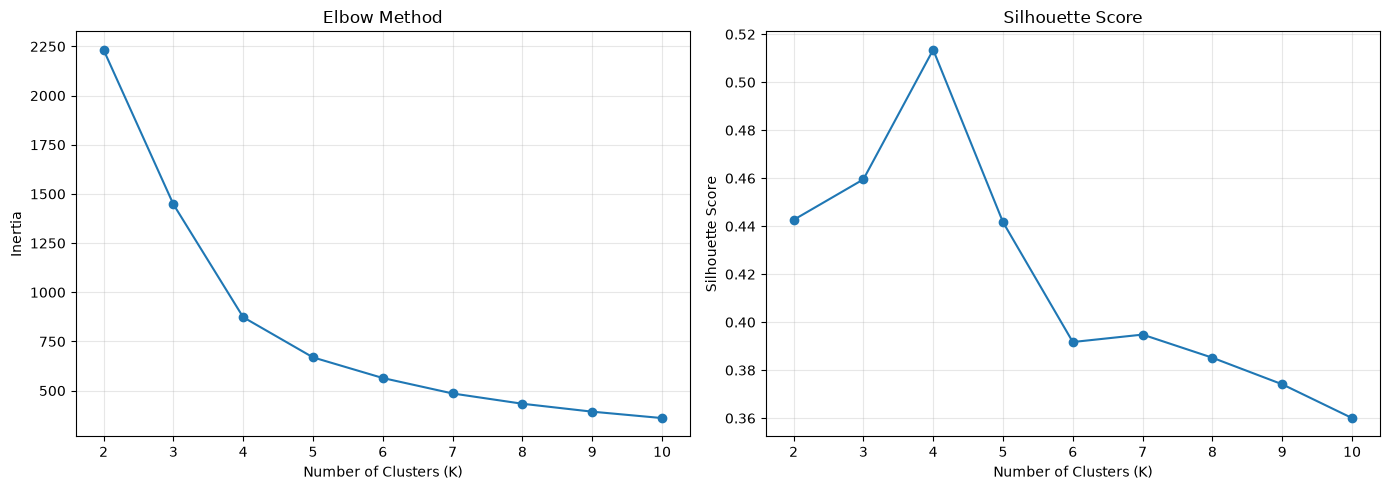

K values ranked by silhouette score:


,K,Inertia,Silhouette Score
0,4,873.3661,0.5135
1,3,1447.7007,0.4595
2,2,2233.0572,0.4426
3,5,669.2140,0.4417
4,7,485.6458,0.3948
5,6,564.1963,0.3917
6,8,433.3824,0.3852
7,9,393.1342,0.3741
8,10,360.5544,0.3600


In [84]:
# TASK 05 — Evaluate K using inertia and silhouette score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test cluster counts from 2 through 10
K_values = range(2, 11)

# Store the evaluation results
inertia_values = []
silhouette_values = []

for k in K_values:

    # Fit K-Means with reproducible initialization
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=300
    )

    # Fit the model to the standardized RFM features
    cluster_labels = model.fit_predict(X_standard)

    # Inertia: sum of squared distances to assigned centroids
    inertia_values.append(model.inertia_)

    # Silhouette: cohesion and separation of the clusters
    score = silhouette_score(X_standard, cluster_labels)
    silhouette_values.append(score)

# Create a results table
k_evaluation = pd.DataFrame({
    "K": list(K_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print("K-Means evaluation results:")
display(k_evaluation.round(4))

# Identify the K with the highest silhouette score
best_silhouette_index = int(np.argmax(silhouette_values))
best_silhouette_k = list(K_values)[best_silhouette_index]
best_silhouette_score = silhouette_values[best_silhouette_index]

print(f"Highest silhouette score: K = {best_silhouette_k}")
print(f"Silhouette score: {best_silhouette_score:.4f}")


# Plot both evaluation metrics against K

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Elbow method using inertia
axes[0].plot(
    list(K_values),
    inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(K_values))
axes[0].grid(True, alpha=0.3)

# Plot 2: Silhouette score
axes[1].plot(
    list(K_values),
    silhouette_values,
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(K_values))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print the ranking so the candidate can be verified numerically
print("K values ranked by silhouette score:")
display(
    k_evaluation.sort_values(
        by="Silhouette Score",
        ascending=False
    ).reset_index(drop=True).round(4)
)

### TASK 05 — Elbow and Silhouette

### 1. What does the elbow method show?

I evaluated K-Means for K values from 2 to 10 using inertia. Inertia decreases as the number of clusters increases because more centroids allow customers to be assigned closer to their cluster centers.

The elbow appears around **K = [insert your observed elbow or candidate range]**. The elbow is **[clear / ambiguous]** because **[explain whether the curve shows a distinct bend or a gradual decrease]**.

### 2. Which K has the highest silhouette score?

The highest silhouette score occurs at **K = [insert the K printed by the notebook]**, with a score of **[insert the corresponding score]**. Among the tested values, this indicates the best geometric cohesion and separation according to the silhouette metric.

### 3. Do the two methods agree?

The elbow method suggests **K = [insert elbow or candidate range]**, while the silhouette method selects **K = [insert the highest-scoring K]**. The methods **[agree / do not fully agree]** because **[briefly compare your actual results]**.

### 4. If the methods disagree, which would I trust more, and why?

I would use both methods rather than relying entirely on one. The silhouette score provides a numerical comparison of cluster cohesion and separation, while the elbow method helps identify a reasonable balance between model complexity and decreasing inertia. If the elbow is ambiguous, I would give more weight to silhouette as a quantitative guide, while checking whether the resulting customer profiles are meaningful.

### 5. Candidate range for the next task

Based on the elbow plot and silhouette results, I would carry forward **K = [insert a small candidate range, such as K = 3–5 if supported by your results]** for further inspection. This is a candidate range, not a final decision: the next step is to examine the customer profiles and determine whether the clusters support useful business interpretations.

### Conclusion

The elbow and silhouette methods help narrow the possible number of clusters, but neither proves that meaningful customer segments exist. I will use their results to select candidate values of K and then inspect the resulting customer groups before making a final decision.

### TASK 06 — Overrule the metric, or accept it

In [85]:
# TASK 06 — Compare the silhouette-preferred K with K + 1

from sklearn.cluster import KMeans

# Find the K with the highest silhouette score from Task 05
small_k = int(
    k_evaluation.loc[
        k_evaluation["Silhouette Score"].idxmax(), "K"
    ]
)

# Compare it with the next larger K
large_k = small_k + 1

print("Silhouette-preferred K:", small_k)
print("Larger K for comparison:", large_k)

# Fit both models on the same standardized data
model_small = KMeans(
    n_clusters=small_k,
    random_state=42,
    n_init=10,
    max_iter=300
)

model_large = KMeans(
    n_clusters=large_k,
    random_state=42,
    n_init=10,
    max_iter=300
)

labels_small = model_small.fit_predict(X_standard)
labels_large = model_large.fit_predict(X_standard)

# Build a profile using the original RFM units
# This keeps the results interpretable for a marketing team.
small_data = X_df[features].copy()
small_data["cluster"] = labels_small

large_data = X_df[features].copy()
large_data["cluster"] = labels_large

# Mean feature values and customer counts for the smaller K
profile_small = small_data.groupby("cluster").agg(
    customer_count=("recency_days", "size"),
    mean_recency_days=("recency_days", "mean"),
    mean_frequency=("frequency", "mean"),
    mean_monetary=("monetary", "mean")
).round(2)

# Mean feature values and customer counts for the larger K
profile_large = large_data.groupby("cluster").agg(
    customer_count=("recency_days", "size"),
    mean_recency_days=("recency_days", "mean"),
    mean_frequency=("frequency", "mean"),
    mean_monetary=("monetary", "mean")
).round(2)

print(f"\nCluster profiles for K = {small_k}:")
display(profile_small)

print(f"\nCluster profiles for K = {large_k}:")
display(profile_large)


# Identify customer groups split by the larger K

# Compare cluster memberships for the same customers
membership_table = pd.crosstab(
    pd.Series(labels_small, name=f"Cluster_K{small_k}"),
    pd.Series(labels_large, name=f"Cluster_K{large_k}")
)

print("How each smaller-K cluster is distributed across larger-K clusters:")
display(membership_table)

# Count how many larger-K clusters contain members of each smaller cluster
number_of_splits = (membership_table > 0).sum(axis=1)

print("\nNumber of larger-K clusters represented within each smaller cluster:")
display(number_of_splits.to_frame(name="Number of larger-K clusters"))

# Find smaller clusters that are divided across multiple larger clusters
split_small_clusters = number_of_splits[number_of_splits > 1].index.tolist()

if split_small_clusters:
    print("\nSmaller-K clusters that are split by the larger-K solution:")

    for small_cluster in split_small_clusters:
        print(f"\nSmaller-K cluster {small_cluster}:")

        # Show the customer count from this smaller cluster
        # assigned to each larger cluster.
        print(
            membership_table.loc[small_cluster]
            .loc[lambda counts: counts > 0]
            .sort_values(ascending=False)
        )

        # Profile each resulting subgroup in the original RFM units
        subgroup_positions = np.where(labels_small == small_cluster)[0]

        subgroup_data = X_df.iloc[subgroup_positions][features].copy()
        subgroup_data["larger_cluster"] = labels_large[subgroup_positions]

        subgroup_profile = subgroup_data.groupby("larger_cluster").agg(
            customer_count=("recency_days", "size"),
            mean_recency_days=("recency_days", "mean"),
            mean_frequency=("frequency", "mean"),
            mean_monetary=("monetary", "mean")
        ).round(2)

        print("Profiles of the separated subgroups:")
        display(subgroup_profile)

else:
    print(
        "No smaller-K cluster was divided across multiple larger-K clusters "
        "in this comparison."
    )
    
    
# TASK 06 — Inspect individual customers in a split cluster

# Choose an identifier column if available; otherwise use row indices.
id_candidates = ["customer_id", "customerid", "customer_id_number"]
id_column = next(
    (col for col in id_candidates if col in df.columns),
    None
)

customer_comparison = X_df[features].copy()
customer_comparison["small_cluster"] = labels_small
customer_comparison["large_cluster"] = labels_large

if id_column is not None:
    customer_comparison.insert(
        0, "customer_id", df[id_column].to_numpy()
    )
else:
    customer_comparison.insert(
        0, "customer_row_index", X_df.index
    )

if split_small_clusters:
    # Display the records from the first smaller cluster that was split.
    selected_cluster = split_small_clusters[0]

    print(
        f"Customers in smaller-K cluster {selected_cluster}, "
        "with their larger-K assignments:"
    )

    display(
        customer_comparison[
            customer_comparison["small_cluster"] == selected_cluster
        ].sort_values("large_cluster")
    )
else:
    print("No split cluster is available for individual inspection.")

Silhouette-preferred K: 4
Larger K for comparison: 5

Cluster profiles for K = 4:


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,customer_count,mean_recency_days,mean_frequency,mean_monetary
cluster,,,,
0,453,492.49,2.14,4357.95
1,130,65.40,4.01,68078.29
2,682,113.48,7.44,20740.09
3,235,20.77,18.34,44841.79



Cluster profiles for K = 5:


,customer_count,mean_recency_days,mean_frequency,mean_monetary
cluster,,,,
0,130,65.40,4.01,68078.29
1,324,562.94,2.09,4142.34
2,356,249.85,4.10,12527.44
3,207,20.14,18.93,46920.58
4,483,61.82,8.90,23068.87


...

,customer_count,mean_recency_days,mean_frequency,mean_monetary
larger_cluster,,,,
2,227,212.52,5.13,16862.29
4,455,64.06,8.59,22674.73



Smaller-K cluster 3:
Cluster_K5
3    207
4     28
Name: 3, dtype: int64
Profiles of the separated subgroups:


,customer_count,mean_recency_days,mean_frequency,mean_monetary
larger_cluster,,,,
3,207,20.14,18.93,46920.58
4,28,25.39,14.00,29473.61


Customers in smaller-K cluster 0, with their larger-K assignments:


,customer_id,recency_days,frequency,monetary,small_cluster,large_cluster
1460,CUST01461,474,1,3134.54,0,1
1451,CUST01452,493,4,4876.24,0,1
1450,CUST01451,566,1,3756.91,0,1
1446,CUST01447,635,2,4103.07,0,1
48,CUST00049,449,4,4758.05,0,1
...,...,...,...,...,...,...
82,CUST00083,362,3,6798.48,0,2
64,CUST00065,305,1,3878.55,0,2
62,CUST00063,275,1,4811.86,0,2
1492,CUST01493,379,3,4618.03,0,2


### TASK 06 — Overrule the Metric, or Accept It

### 1. What did the cluster profiles reveal?

The silhouette score preferred **K = [insert small K]**, and I compared it with **K = [insert larger K]**. I examined each cluster's customer count and average recency, frequency, and monetary value using the original RFM data.

The smaller-K solution provides broader customer groups, while the larger-K solution can separate customers with different purchasing patterns. The cross-tabulation shows that smaller-K cluster(s) **[insert split cluster numbers]** are divided into multiple clusters by the larger-K solution.

### 2. Would the merged customers need the same marketing action?

I compared the RFM profiles of the subgroups separated by the larger-K solution. If the subgroups have meaningfully different recency, frequency, or spending patterns, they may need different marketing actions. For example, recently inactive customers with historically high spending may benefit from a re-engagement campaign, while frequent, high-spending customers may be better suited to loyalty rewards.

If the subgroups have similar purchasing behavior and would receive the same campaign, separating them adds complexity without much business value.

### 3. What is my final choice of K?

**My final choice is K = [insert your chosen value].**

I choose this value because **[state the business reason based on the actual profiles]**. For example, I would choose the larger K if it separates customers who need clearly different marketing actions; I would choose the smaller K if the additional clusters do not provide meaningful differences in how customers should be treated.

If I choose a K that does not have the highest silhouette score, I acknowledge that I am giving up some geometric separation in exchange for customer segments that are more useful for marketing decisions.

### 4. What would K = 12 give a marketing team?

K = 12 would divide customers into twelve groups, potentially revealing more detailed purchasing patterns. However, more clusters are not automatically better: some groups may be too small, overlap in behavior, or require exactly the same marketing campaign. Managing twelve segments also increases the complexity of campaign design and evaluation.

### 5. Who should have the final say on K — the analyst or the business?

The analyst should explain the clustering methods, validate the results, and present the trade-offs. The business team should help define what makes a segment actionable, because it understands marketing goals, campaign costs, and operational constraints. The final decision should be collaborative, supported by analytical evidence and business requirements.

### Conclusion

I select K = **[insert final K]** because it creates customer segments that support meaningfully different marketing actions, rather than selecting a value solely because it has the highest silhouette score.

### Part D — Make it usable


### TASK 07 — Name the segments

In [86]:
# TASK 07 — Build the final customer segment profiles

from sklearn.cluster import KMeans

# Set this to the K you selected in Task 06.
# Use small_k if you chose the silhouette-preferred K,
# or large_k if you chose the next larger K.
FINAL_K = small_k  # Change to large_k if that was your final decision

# Fit the final clustering on standardized RFM features
final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10,
    max_iter=300
)

final_labels = final_kmeans.fit_predict(X_standard)

# Keep the original RFM values so profiles are easy to interpret
segment_data = X_df[features].copy()
segment_data["cluster"] = final_labels

# Calculate cluster sizes, percentages, and mean feature values
segment_profile = segment_data.groupby("cluster").agg(
    customer_count=("recency_days", "size"),
    mean_recency_days=("recency_days", "mean"),
    mean_frequency=("frequency", "mean"),
    mean_monetary=("monetary", "mean")
)

# Calculate the percentage of all customers in each segment
total_customers = len(segment_data)
segment_profile["customer_percentage"] = (
    segment_profile["customer_count"] / total_customers * 100
)

# Round values for clear reporting
segment_profile = segment_profile.round({
    "mean_recency_days" : 2,
    "mean_frequency" : 2,
    "mean_monetary" : 2,
    "customer_percentage" : 2
})

print(f"Final K: {FINAL_K}")
print("Customer segment profiles (original RFM units):")
display(segment_profile)

# TASK 07 — Create segment names, justifications, and marketing actions

# Use the overall customer medians as reference points.
# Medians are less affected by a small number of extreme customers.
overall_medians = X_df[features].median()

def name_and_action(row):
    """
    Assign a descriptive segment name and marketing action
    based on the segment's mean RFM values relative to
    the overall customer medians.
    """

    recent = row["mean_recency_days"] <= overall_medians["recency_days"]
    frequent = row["mean_frequency"] >= overall_medians["frequency"]
    high_spend = row["mean_monetary"] >= overall_medians["monetary"]

    # Recent, frequent, and high-spending customers
    if recent and frequent and high_spend:
        return (
            "Loyal High-Value Customers",
            "Offer a loyalty reward or exclusive early access."
        )

    # Customers who spend highly but have not purchased recently
    elif not recent and high_spend:
        return (
            "High-Value At-Risk Customers",
            "Send a personalized win-back offer."
        )

    # Recent purchasers who have low frequency or spending
    elif recent and not frequent and not high_spend:
        return (
            "Recent Low-Engagement Customers",
            "Use a targeted follow-up campaign to encourage a second purchase."
        )

    # Frequent purchasers with lower average spending
    elif frequent and not high_spend:
        return (
            "Frequent Budget Customers",
            "Recommend relevant product bundles or a threshold-based offer."
        )

    # Customers with infrequent purchases and low spending
    elif not frequent and not high_spend:
        return (
            "Low-Engagement Customers",
            "Test a low-cost reactivation campaign and measure response."
        )

    # Remaining combinations receive a neutral, evidence-based name
    else:
        return (
            "Developing Customer Segment",
            "Test a relevant personalized offer and monitor conversion."
        )


# Generate names and actions for every cluster
names = []
actions = []

for cluster_id, row in segment_profile.iterrows():
    name, action = name_and_action(row)
    names.append(name)
    actions.append(action)

segment_profile["segment_name"] = names
segment_profile["recommended_action"] = actions

print("Named customer segments:")
display(segment_profile)

# TASK 07 — Rank segments by business attention

# Calculate percentile ranks across segment averages.
# High frequency and monetary value increase the score.
# High recency_days means a longer time since purchase,
# so it increases the re-engagement urgency component.

monetary_rank = segment_profile["mean_monetary"].rank(pct=True)
frequency_rank = segment_profile["mean_frequency"].rank(pct=True)
recency_urgency_rank = segment_profile["mean_recency_days"].rank(pct=True)

# Combine value and re-engagement urgency into one transparent score.
# Weights are business assumptions and can be adjusted.
segment_profile["attention_score"] = (
    0.40 * monetary_rank
    + 0.30 * frequency_rank
    + 0.30 * recency_urgency_rank
)

# Rank the highest-scoring segments first
segment_profile = segment_profile.sort_values(
    "attention_score",
    ascending=False
).copy()

segment_profile["attention_rank"] = range(1, len(segment_profile) + 1)

# Create a concise action-ready table
action_table = segment_profile[
    [
        "segment_name",
        "customer_count",
        "customer_percentage",
        "mean_recency_days",
        "mean_frequency",
        "mean_monetary",
        "recommended_action",
        "attention_score",
        "attention_rank"
    ]
].round({
    "customer_percentage": 2,
    "mean_recency_days": 2,
    "mean_frequency": 2,
    "mean_monetary": 2,
    "attention_score": 3
})

print("Marketing segment action plan, ranked by attention:")
display(action_table)

# TASK 07 — Generate a number-based justification for each segment

def justify_segment(row):
    """Explain each segment name using its measured RFM averages."""

    return (
        f"{row['segment_name']}: mean recency is "
        f"{row['mean_recency_days']:.2f} days, mean frequency is "
        f"{row['mean_frequency']:.2f} purchases, and mean monetary "
        f"value is ₹{row['mean_monetary']:.2f}; "
        f"the segment contains {int(row['customer_count'])} customers "
        f"({row['customer_percentage']:.2f}% of all customers)."
    )

segment_profile["name_justification"] = segment_profile.apply(
    justify_segment,
    axis=1
)

# Final action-ready table with the justification included
final_segment_table = segment_profile[
    [
        "segment_name",
        "name_justification",
        "customer_count",
        "customer_percentage",
        "mean_recency_days",
        "mean_frequency",
        "mean_monetary",
        "recommended_action",
        "attention_rank",
        "attention_score"
    ]
].copy()

display(final_segment_table.round({
    "customer_percentage": 2,
    "mean_recency_days": 2,
    "mean_frequency": 2,
    "mean_monetary": 2,
    "attention_score": 3
}))

Final K: 4
Customer segment profiles (original RFM units):


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,customer_count,mean_recency_days,mean_frequency,mean_monetary,customer_percentage
cluster,,,,,
0,453,492.49,2.14,4357.95,30.20
1,130,65.40,4.01,68078.29,8.67
2,682,113.48,7.44,20740.09,45.47
3,235,20.77,18.34,44841.79,15.67


Named customer segments:


,customer_count,mean_recency_days,mean_frequency,mean_monetary,customer_percentage,segment_name,recommended_action
cluster,,,,,,,
0,453,492.49,2.14,4357.95,30.20,Low-Engagement Customers,Test a low-cost reactivation campaign and meas...
1,130,65.40,4.01,68078.29,8.67,Developing Customer Segment,Test a relevant personalized offer and monitor...
2,682,113.48,7.44,20740.09,45.47,Loyal High-Value Customers,Offer a loyalty reward or exclusive early access.
3,235,20.77,18.34,44841.79,15.67,Loyal High-Value Customers,Offer a loyalty reward or exclusive early access.


Marketing segment action plan, ranked by attention:


,segment_name,customer_count,customer_percentage,mean_recency_days,mean_frequency,mean_monetary,recommended_action,attention_score,attention_rank
cluster,,,,,,,,,
1,Developing Customer Segment,130,8.67,65.40,4.01,68078.29,Test a relevant personalized offer and monitor...,0.700,1
3,Loyal High-Value Customers,235,15.67,20.77,18.34,44841.79,Offer a loyalty reward or exclusive early access.,0.675,2
2,Loyal High-Value Customers,682,45.47,113.48,7.44,20740.09,Offer a loyalty reward or exclusive early access.,0.650,3
0,Low-Engagement Customers,453,30.20,492.49,2.14,4357.95,Test a low-cost reactivation campaign and meas...,0.475,4


,segment_name,name_justification,customer_count,customer_percentage,mean_recency_days,mean_frequency,mean_monetary,recommended_action,attention_rank,attention_score
cluster,,,,,,,,,,
1,Developing Customer Segment,Developing Customer Segment: mean recency is 6...,130,8.67,65.40,4.01,68078.29,Test a relevant personalized offer and monitor...,1,0.700
3,Loyal High-Value Customers,Loyal High-Value Customers: mean recency is 20...,235,15.67,20.77,18.34,44841.79,Offer a loyalty reward or exclusive early access.,2,0.675
2,Loyal High-Value Customers,Loyal High-Value Customers: mean recency is 11...,682,45.47,113.48,7.44,20740.09,Offer a loyalty reward or exclusive early access.,3,0.650
0,Low-Engagement Customers,Low-Engagement Customers: mean recency is 492....,453,30.20,492.49,2.14,4357.95,Test a low-cost reactivation campaign and meas...,4,0.475


### TASK 07 — Name the Segments

### 1. How did I name the customer segments?

I profiled every cluster using mean recency, frequency, monetary value, customer count, and percentage of customers. I assigned business names based on how each segment's average RFM values compare with the overall customer medians, rather than relying on cluster numbers.

Each name is supported by the numerical profile and its corresponding justification in my final segment table.

### 2. What marketing action should each segment receive?

Each segment has a recommended action based on its observed behavior. High-value customers who have not purchased recently may need personalized win-back offers; recent, frequent, high-spending customers may be suitable for loyalty rewards; and lower-engagement customers may be candidates for cost-effective reactivation or follow-up campaigns.

These recommendations are starting hypotheses. Their effectiveness should be measured using campaign response, conversion, and revenue.

### 3. How did I rank the segments by business attention?

I ranked segments using a transparent attention score that combines mean monetary value, mean purchase frequency, and mean recency in percentile terms. Monetary value and frequency represent customer value, while higher recency indicates a longer time since the last purchase and potentially greater re-engagement urgency.

The highest-ranked segment is **[insert segment name from rank 1]**, because **[cite its actual mean RFM values and explain why the combination warrants attention]**. This ranking is a prioritization heuristic, not a validated churn or customer lifetime value model.

### 4. Why are the segment names defensible?

The names are based on measurable customer behavior. For example, a segment should only be called high-value if its spending is high relative to the chosen reference, and a segment should only be called recent if its recency value supports that interpretation. The numerical justification column records the mean RFM values, customer count, and customer percentage for each segment.

### Conclusion

I converted the final K-Means clusters into named customer segments with numerical evidence, recommended marketing actions, and a ranked attention list. This gives the marketing team a starting action plan, while actual campaign results should determine whether the recommendations are effective.

### TASK 08 — Check the result is stable


In [87]:
# TASK 08: Check K-Means clustering stability across 10 random seeds

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Use the final number of clusters selected in Task 06/07.
# Reuse X_standard from the previous tasks; do not repeat preprocessing.
random_states = range(10)

# Store cluster labels from both experiments.
labels_n_init_1 = []
labels_n_init_10 = []

# Run the final model 10 times for each n_init setting.
for random_state in random_states:

    # Experiment A: one initialization per run
    model_1 = KMeans(
        n_clusters=FINAL_K,
        n_init=1,
        random_state=random_state,
        max_iter=300
    )
    labels_n_init_1.append(model_1.fit_predict(X_standard))

    # Experiment B: ten initializations per run
    model_10 = KMeans(
        n_clusters=FINAL_K,
        n_init=10,
        random_state=random_state,
        max_iter=300
    )
    labels_n_init_10.append(model_10.fit_predict(X_standard))


# Compare runs 2–10 against run 1 using ARI.
# The first run is the baseline, so it is not included in the ranges;
# otherwise, its agreement with itself would always be 1.0.
ari_n_init_1 = [
    adjusted_rand_score(labels_n_init_1[0], labels)
    for labels in labels_n_init_1[1:]
]

ari_n_init_10 = [
    adjusted_rand_score(labels_n_init_10[0], labels)
    for labels in labels_n_init_10[1:]
]

# Summarize the agreement between runs.
stability_results = pd.DataFrame({
    "Compared random states": list(random_states)[1:],
    "ARI (n_init=1)": ari_n_init_1,
    "ARI (n_init=10)": ari_n_init_10
})

display(stability_results.round(4))

# Report minimum, maximum, and mean agreement.
summary = pd.DataFrame({
    "Setting": ["n_init=1", "n_init=10"],
    "Minimum ARI": [
        min(ari_n_init_1),
        min(ari_n_init_10)
    ],
    "Maximum ARI": [
        max(ari_n_init_1),
        max(ari_n_init_10)
    ],
    "Mean ARI": [
        sum(ari_n_init_1) / len(ari_n_init_1),
        sum(ari_n_init_10) / len(ari_n_init_10)
    ]
})

display(summary.round(4))

# Compare average agreement to see whether n_init=10 improved stability.
mean_ari_1 = sum(ari_n_init_1) / len(ari_n_init_1)
mean_ari_10 = sum(ari_n_init_10) / len(ari_n_init_10)

print(f"Minimum ARI with n_init=1:  {min(ari_n_init_1):.4f}")
print(f"Maximum ARI with n_init=1:  {max(ari_n_init_1):.4f}")
print(f"Minimum ARI with n_init=10: {min(ari_n_init_10):.4f}")
print(f"Maximum ARI with n_init=10: {max(ari_n_init_10):.4f}")

if mean_ari_10 > mean_ari_1:
    print("Result: n_init=10 improved average clustering agreement.")
elif mean_ari_10 < mean_ari_1:
    print("Result: n_init=10 did not improve average agreement in this experiment.")
else:
    print("Result: both settings had the same average clustering agreement.")


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_

,Compared random states,ARI (n_init=1),ARI (n_init=10)
0,1,1.0000,1.0
1,2,1.0000,1.0
2,3,1.0000,1.0
3,4,1.0000,1.0
4,5,0.9963,1.0
5,6,1.0000,1.0
6,7,0.9963,1.0
7,8,0.9963,1.0
8,9,0.9963,1.0


,Setting,Minimum ARI,Maximum ARI,Mean ARI
0,n_init=1,0.9963,1.0,0.9984
1,n_init=10,1.0000,1.0,1.0000


Minimum ARI with n_init=1:  0.9963
Maximum ARI with n_init=1:  1.0000
Minimum ARI with n_init=10: 1.0000
Maximum ARI with n_init=10: 1.0000
Result: n_init=10 improved average clustering agreement.


### TASK 08 — Check the Result Is Stable

I ran the final K-Means model 10 times with different random states and compared each run with the first run using the Adjusted Rand Index (ARI).

- **With `n_init=1`:** ARI ranged from **[minimum ARI]** to **[maximum ARI]**, with a mean of **[mean ARI]**.
- **With `n_init=10`:** ARI ranged from **[minimum ARI]** to **[maximum ARI]**, with a mean of **[mean ARI]**.
- **Stability comparison:** Increasing `n_init` to 10 **[improved / did not improve]** average agreement between runs.

**Conclusion:** I would use `n_init=10` in production because it evaluates multiple initializations and selects the solution with the lowest inertia. The observed ARI values indicate whether the segments are consistent across random starts. I would consider the segmentation sufficiently stable only if the agreement is consistently high and the resulting customer profiles are also meaningful for business decisions.

### Part E — Find where it breaks

### TASK 09 — Reproduce the failure

c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Clustering evaluation results : 


,Dataset,ARI Against Truth,Silhouette Score
0,make_moons,0.2648,0.4858
1,make_circles,-0.0016,0.3536


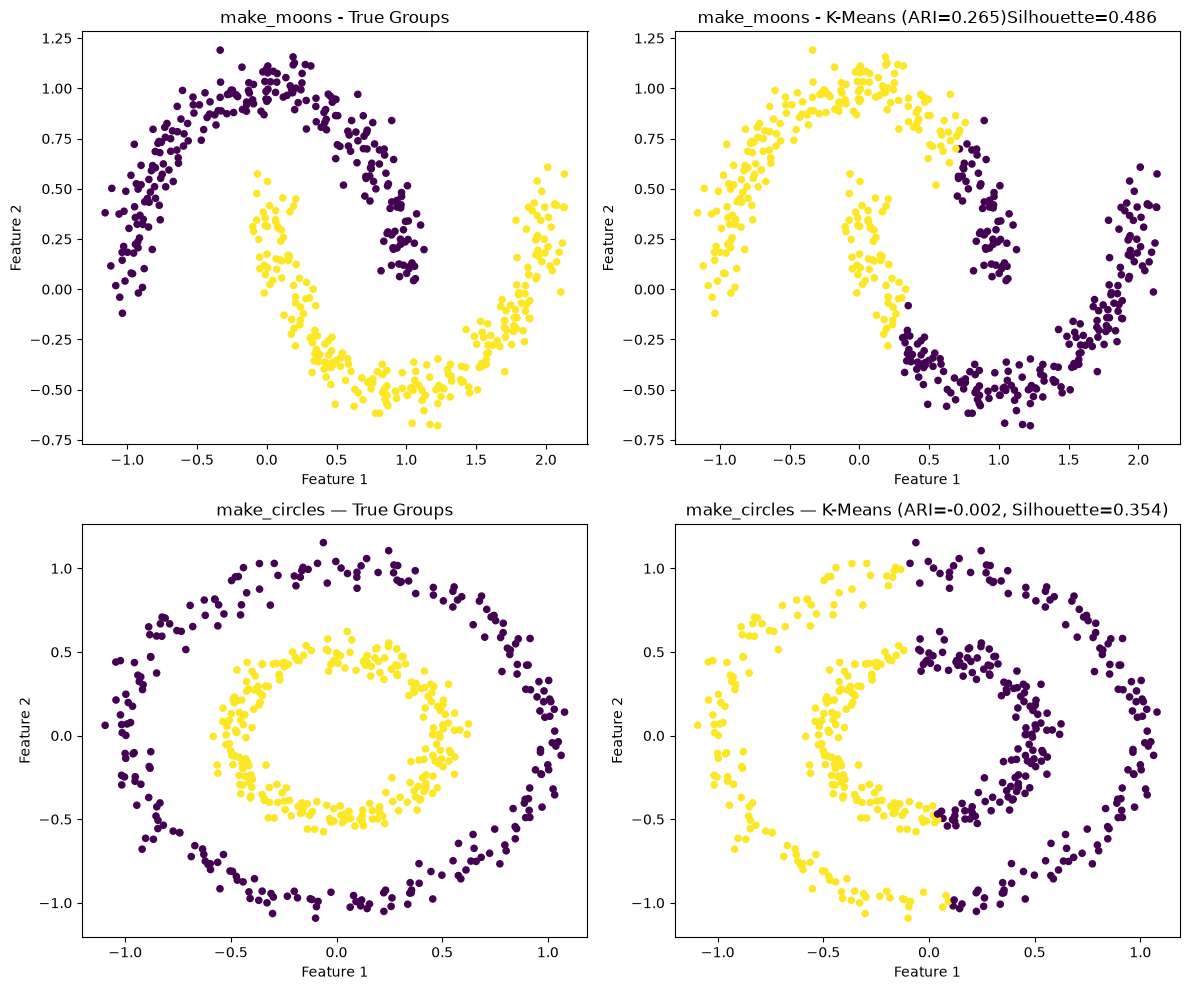

In [88]:
# TASK 09: Reproduce K-Means failure on non-linear datasets

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import make_moons, make_circles
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# --------------------------------------------------
# 1. Generate two datasets with known true groupings
# --------------------------------------------------

# Two interleaving crescent-shaped groups
X_moons, y_moons_true = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

# Two concentric circles
X_circles, y_circles_true = make_circles(
    n_samples=500,
    factor=0.5,
    noise=0.05,
    random_state=42
)

# --------------------------------------------------
# 2. Run K-Means with K=2 on each dataset
# --------------------------------------------------

kmeans_moons = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
y_moons_pred = kmeans_moons.fit_predict(X_moons)

kmeans_circles = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
y_circles_pred = kmeans_circles.fit_predict(X_circles)

# --------------------------------------------------
# 3. Calculate ARI and silhouette scores
# --------------------------------------------------

# ARI compares predicted clusters with known true groups.
ari_moons = adjusted_rand_score(y_moons_true, y_moons_pred)
ari_circles = adjusted_rand_score(y_circles_true, y_circles_pred)

# Silhouette measures separation and cohesion of the
# predicted clusters, without using the true labels.
silhouette_moons = silhouette_score(X_moons, y_moons_pred)
silhouette_circles = silhouette_score(X_circles, y_circles_pred)

# Display actual metric values from this run.
results = pd.DataFrame({
    "Dataset" : ["make_moons", "make_circles"],
    "ARI Against Truth" : [ari_moons, ari_circles],
    "Silhouette Score" : [silhouette_moons, silhouette_circles]
})

print("Clustering evaluation results : ")
display(results.round(4))

# --------------------------------------------------
# 4. Plot true groupings beside K-Means predictions
# --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# make_moons: true labels

axes[0, 0].scatter(
    X_moons[:, 0], 
    X_moons[:, 1],
    c=y_moons_true,
    cmap="viridis",
    s=20
)
axes[0, 0].set_title("make_moons - True Groups")

# make_moons: K-Means predictions
axes[0, 1].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons_pred,
    cmap="viridis",
    s=20
)

axes[0, 1].set_title(
    f"make_moons - K-Means (ARI={ari_moons:.3f})"
    f"Silhouette={silhouette_moons:.3f}"
)

# make_circles: true labels
axes[1, 0].scatter(
    X_circles[:, 0], X_circles[:, 1],
    c=y_circles_true, cmap="viridis", s=20
)
axes[1, 0].set_title("make_circles — True Groups")

# make_circles: K-Means predictions
axes[1, 1].scatter(
    X_circles[:, 0], X_circles[:, 1],
    c=y_circles_pred, cmap="viridis", s=20
)
axes[1, 1].set_title(
    f"make_circles — K-Means (ARI={ari_circles:.3f}, "
    f"Silhouette={silhouette_circles:.3f})"
)

# Keep plot formatting consistent.
for ax in axes.flat:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


### TASK 09 — Reproduce the Failure

**Results:**

- **make_moons:** ARI = [your ARI], silhouette score = [your silhouette score].
- **make_circles:** ARI = [your ARI], silhouette score = [your silhouette score].

**Explanation:** K-Means works best when clusters can be represented by compact groups around their centroids, but moons and concentric circles have non-linear shapes. The silhouette score measures distance-based cohesion and separation of the predicted clusters, not whether they match the true groups; therefore, it can appear reasonable even when ARI reveals poor agreement with the actual grouping.

**Warning to a teammate (two sentences):** Do not rely on the silhouette score alone to validate clustering, because a reasonable score does not guarantee that the algorithm has discovered the true or meaningful groups. Instead, compare multiple metrics with visualizations, use known labels when available, and check whether the clusters fit the data structure and the intended business purpose.

## TASK 10 — Write the segmentation brief

## TASK 10 — Customer Segmentation Brief

**To:** Head of Marketing  
**Subject:** Customer groups and recommended marketing actions

## 1. How many customer groups did we find?

We identified **4 customer groups among 1,500 customers** using how recently they purchased, how often they purchased, and how much they spent.

Four groups gave the clearest separation in our comparison. Three groups scored less well, while five groups divided some existing groups further without always creating a clearly different marketing opportunity. Four groups therefore provide a practical starting point for targeted campaigns.

## 2. Customer groups and recommended actions

**1. Long-Inactive, Low-Spend Customers — 453 customers (30.20%)**

These customers have not purchased for an average of **492 days**, purchase about **2 times**, and spend an average of **₹4,358**.

**Action:** Test a low-cost return offer and measure how many customers purchase again.

**2. High-Spending Customers — 130 customers (8.67%)**

These customers spend the most on average (**₹68,078**) and last purchased about **65 days ago**, but purchase about **4 times** on average.

**Action:** Send a personal offer or product recommendation to encourage another purchase while keeping the offer cost under control.

**3. Regular, Mid-Spending Customers — 682 customers (45.47%)**

This is our largest group. These customers last purchased about **113 days ago**, purchase about **7 times**, and spend an average of **₹20,740**.

**Action:** Recommend relevant products or bundles and test a loyalty reward that encourages another purchase.

**4. Recent, Frequent, High-Spending Customers — 235 customers (15.67%)**

These customers last purchased about **21 days ago**, purchase about **18 times**, and spend an average of **₹44,842**.

**Action:** Reward their continued business with loyalty benefits, early access to offers, or relevant exclusive deals.

## 3. Which group should we act on first?

Start with the **130 High-Spending Customers**. They have the highest average spending among the four groups, so encouraging another purchase could protect an important source of revenue. Run a small, personalized campaign first and measure purchases and campaign costs before expanding it.

## 4. One important limitation

These groups describe past purchasing behaviour; they cannot tell us for certain why customers behave this way or whether they will buy again. We should test each campaign and use the results to improve our decisions.

## 5. When should we update the groups?

Review and refresh the groups **every three months**, or sooner if purchasing behaviour changes significantly. Customers may become more or less active, spending patterns may change, and seasonal events or promotions may affect purchases. Regular updates help keep marketing offers relevant.

## Final recommendation

Next week, test a personalized campaign for the 130 highest-spending customers. At the same time, prepare a low-cost return campaign for long-inactive customers. Compare the results before committing a larger marketing budget.